# 03 — Phân tích thời gian (theo giờ địa phương)

Câu hỏi:
1. Dữ liệu được thu thập khi nào (năm/tháng), mỗi user tham gia bao lâu, liên tục hay rời rạc?
2. Giờ UTC vs giờ địa phương: sai lệch nếu không đổi timezone lớn thế nào?
3. Pattern theo giờ trong ngày / ngày trong tuần / ngày lễ.
4. **Độ phủ ban đêm và giờ hành chính** — điều kiện cần để suy luận home/office.

Giờ địa phương = `ts_utc + utc_offset_h` (offset theo timezone của toạ độ, tính ở NB02).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import PROCESSED, load_points, savefig, setup_style

setup_style()
pts = load_points(["user", "traj_id", "ts_utc"])
pts["rid"] = np.arange(len(pts), dtype="int64")
geo = pd.read_parquet(PROCESSED / "points_geo.parquet", columns=["rid", "utc_offset_h", "in_beijing"])
pts = pts.merge(geo, on="rid", how="inner")
pts["utc_offset_h"] = pts.utc_offset_h.fillna(8)
pts["ts_local"] = pts.ts_utc + pd.to_timedelta(pts.utc_offset_h, unit="h")
pts = pts[pts.ts_utc.dt.year >= 2007]  # bỏ 3 điểm năm 2000 (lỗi đồng hồ)
pts["date"] = pts.ts_local.dt.normalize()
pts["hour"] = pts.ts_local.dt.hour
pts["dow"] = pts.ts_local.dt.day_of_week  # 0=Mon
print(len(pts))

24876974


## 1. Dòng thời gian thu thập

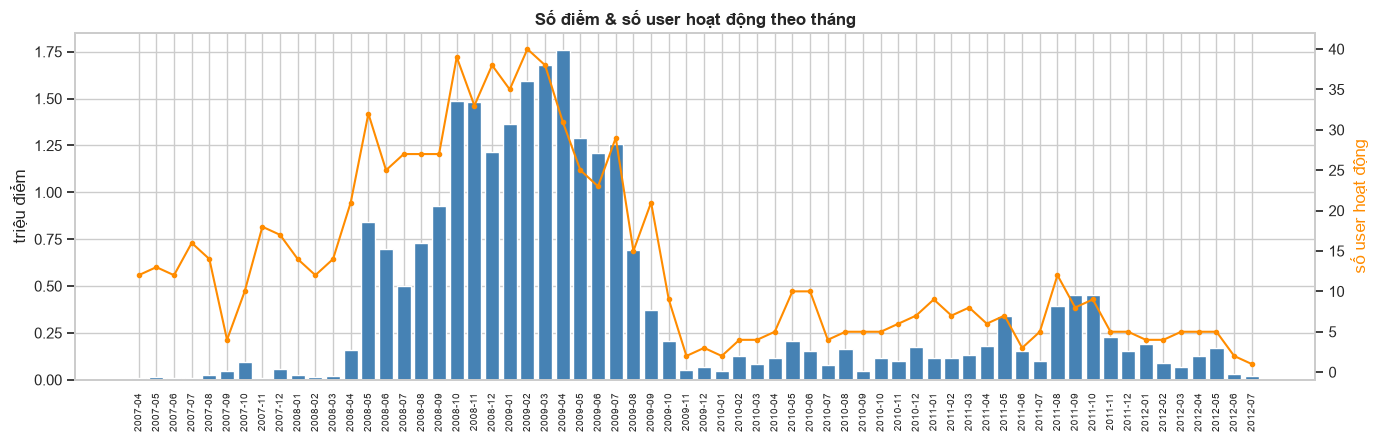

,n,users
ts_local,,
2009-04,1760243,31
2009-03,1679739,38
2009-02,1594544,40
2008-10,1487596,39
2008-11,1483523,33
2009-01,1364419,35
2009-05,1289005,25
2009-07,1260048,29


In [2]:
monthly = pts.groupby(pts.ts_local.dt.to_period("M")).agg(n=("user", "size"), users=("user", "nunique"))
fig, ax1 = plt.subplots(figsize=(16, 4.5))
ax1.bar(monthly.index.astype(str), monthly.n / 1e6, color="steelblue")
ax1.set_ylabel("triệu điểm"); ax1.tick_params(axis="x", rotation=90, labelsize=7)
ax2 = ax1.twinx(); ax2.plot(monthly.index.astype(str), monthly.users, c="darkorange", marker="o", ms=3)
ax2.set_ylabel("số user hoạt động", color="darkorange"); ax2.grid(False)
ax1.set_title("Số điểm & số user hoạt động theo tháng")
savefig("03_monthly"); plt.show()
monthly.sort_values("n", ascending=False).head(8)

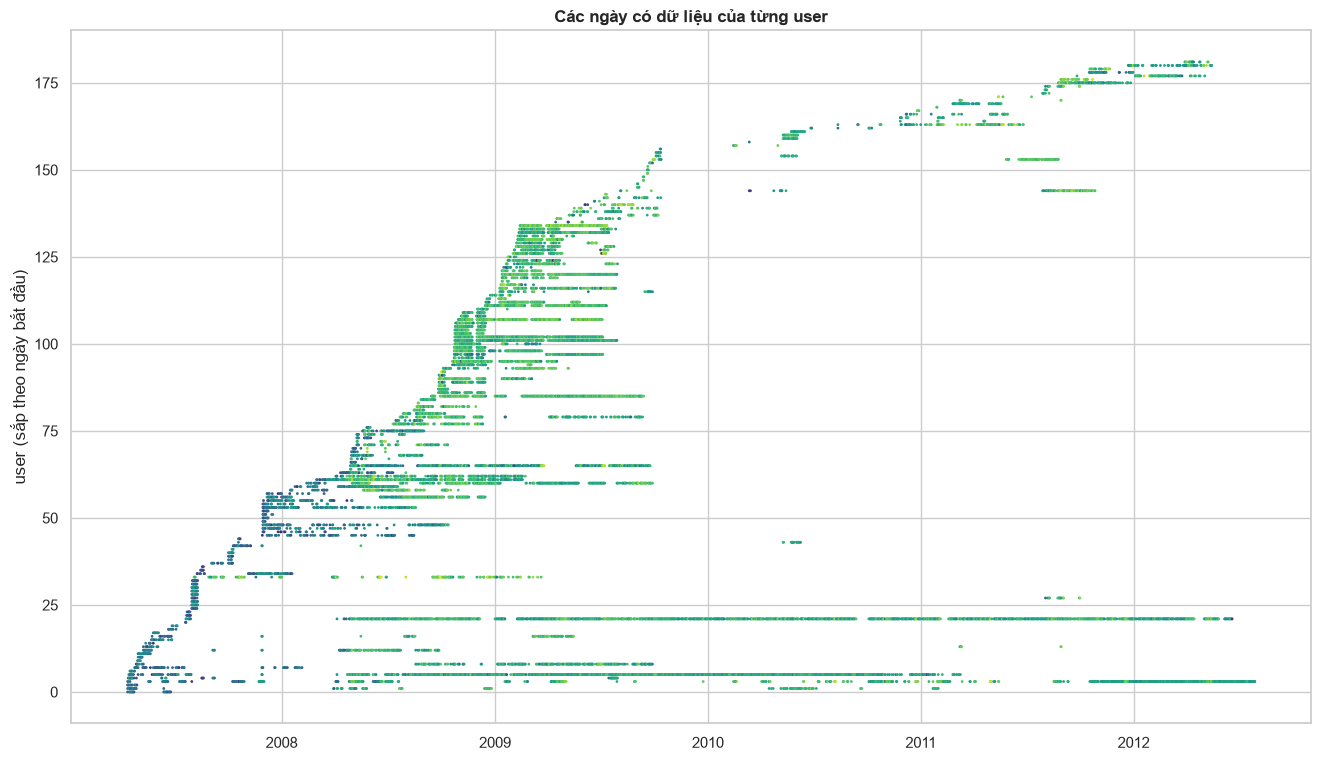

In [3]:
# "Gantt": mỗi user là 1 hàng, mỗi chấm là 1 ngày có dữ liệu
ud = pts.groupby(["user", "date"]).size().reset_index(name="n")
order = ud.groupby("user").date.min().sort_values().index
ymap = {u: i for i, u in enumerate(order)}
fig, ax = plt.subplots(figsize=(16, 9))
ax.scatter(ud.date, ud.user.map(ymap), s=1, c=np.log10(ud.n), cmap="viridis")
ax.set_ylabel("user (sắp theo ngày bắt đầu)"); ax.set_title("Các ngày có dữ liệu của từng user")
savefig("03_user_gantt"); plt.show()

       active_days  span_days  coverage
count     182.0000   182.0000  182.0000
mean       61.2912   174.4615    0.5456
std       131.6167   318.5571    0.3023
min         1.0000     1.0000    0.0114
10%         4.0000     5.1000    0.1285
25%         7.0000    11.0000    0.2978
50%        21.5000    71.5000    0.5153
75%        63.0000   168.2500    0.8000
90%       133.3000   363.9000    1.0000
max     1,252.0000 1,934.0000    1.0000


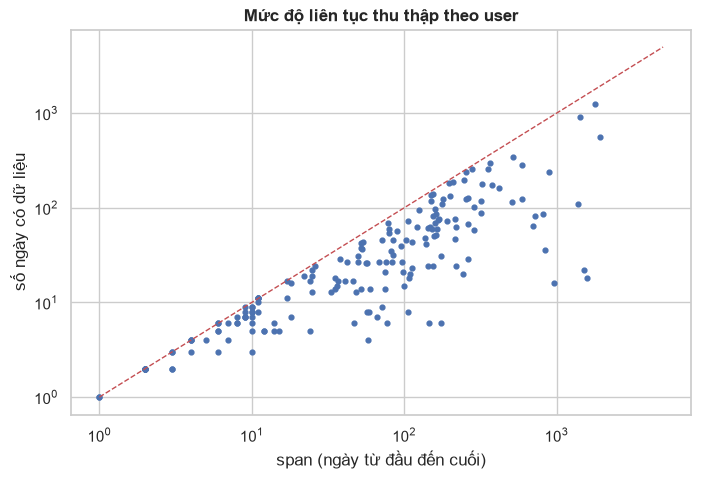

In [4]:
act = ud.groupby("user").agg(first=("date", "min"), last=("date", "max"), active_days=("date", "nunique"))
act["span_days"] = (act["last"] - act["first"]).dt.days + 1
act["coverage"] = act.active_days / act.span_days
print(act[["active_days", "span_days", "coverage"]].describe(percentiles=[.1, .25, .5, .75, .9]))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(act.span_days, act.active_days, s=12)
ax.set_xscale("log"); ax.set_yscale("log"); ax.plot([1, 5000], [1, 5000], "r--", lw=1)
ax.set_xlabel("span (ngày từ đầu đến cuối)"); ax.set_ylabel("số ngày có dữ liệu"); ax.set_title("Mức độ liên tục thu thập theo user")
savefig("03_span_vs_active"); plt.show()

In [5]:
# Khoảng ngừng dài nhất giữa 2 ngày hoạt động liên tiếp của user
ud_sorted = ud.sort_values(["user", "date"])
ud_sorted["gap_days"] = ud_sorted.groupby("user").date.diff().dt.days
print(ud_sorted.groupby("user").gap_days.max().describe(percentiles=[.25, .5, .75, .9]))
print("Phân bố gap giữa 2 ngày hoạt động liên tiếp:")
print(pd.cut(ud_sorted.gap_days.dropna(), [0, 1, 2, 7, 30, 180, 10_000]).value_counts(normalize=True).sort_index())

count     180.0000
mean       64.0222
std       184.1033
min         1.0000
25%         3.0000
50%        12.5000
75%        41.5000
90%       108.2000
max     1,455.0000
Name: gap_days, dtype: float64
Phân bố gap giữa 2 ngày hoạt động liên tiếp:
gap_days
(0, 1]         0.8155
(1, 2]         0.0797
(2, 7]         0.0696
(7, 30]        0.0261
(30, 180]      0.0080
(180, 10000]   0.0012
Name: proportion, dtype: float64


**Insight:** coverage (ngày có dữ liệu / span) thấp với nhiều user → dữ liệu **thưa và rời rạc theo ngày**; user có thể đổi nhà/công ty
trong span dài (vd. user 153 span ~5 năm) → nên xét home/office theo **cửa sổ thời gian** (vd. theo tháng/quý) hoặc kiểm tra tính ổn định.

## 2. UTC vs giờ địa phương

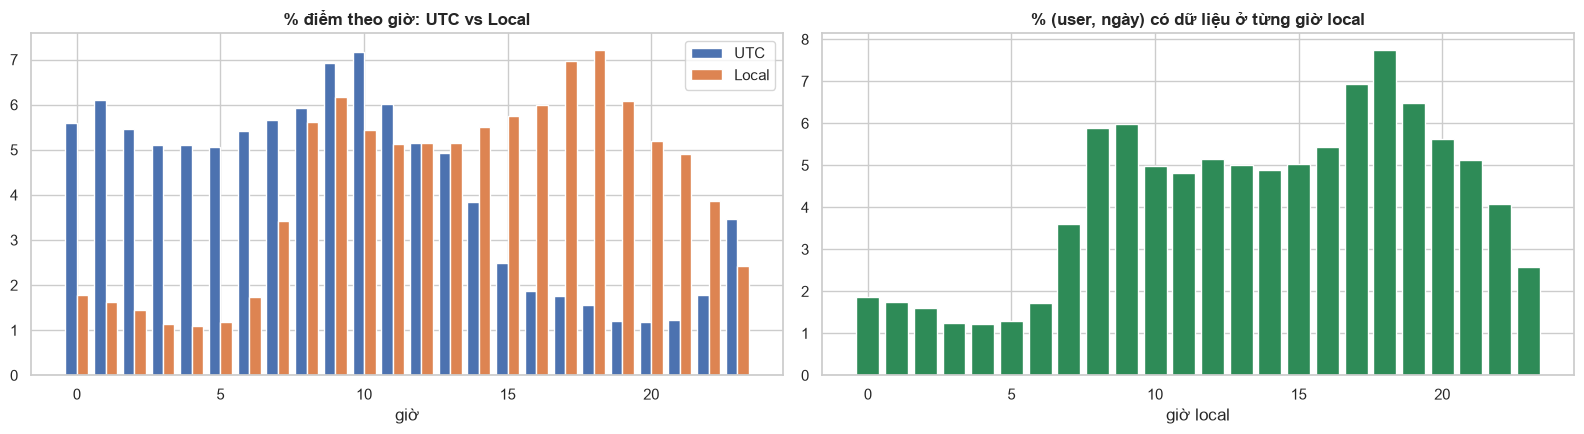

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
h_utc = pts.ts_utc.dt.hour.value_counts(normalize=True).sort_index() * 100
h_loc = pts.hour.value_counts(normalize=True).sort_index() * 100
axes[0].bar(h_utc.index - 0.2, h_utc.values, width=0.4, label="UTC")
axes[0].bar(h_loc.index + 0.2, h_loc.values, width=0.4, label="Local")
axes[0].legend(); axes[0].set_title("% điểm theo giờ: UTC vs Local"); axes[0].set_xlabel("giờ")
# Theo số user-ngày có hoạt động ở mỗi giờ (bớt bias power user)
uh = pts.groupby(["user", "date", "hour"]).size().reset_index().groupby("hour").size()
axes[1].bar(uh.index, uh.values / uh.sum() * 100, color="seagreen")
axes[1].set_title("% (user, ngày) có dữ liệu ở từng giờ local"); axes[1].set_xlabel("giờ local")
plt.tight_layout(); savefig("03_hour_utc_vs_local"); plt.show()

**Insight:** Nếu dùng nhầm UTC, đỉnh hoạt động buổi sáng/chiều bị dịch 8 tiếng — "ban đêm" theo UTC (0–6h UTC) thực chất là
8–14h tại Bắc Kinh, tức giờ làm việc. Nhầm timezone sẽ đảo ngược nhãn home/office.

## 3. Pattern giờ × ngày trong tuần

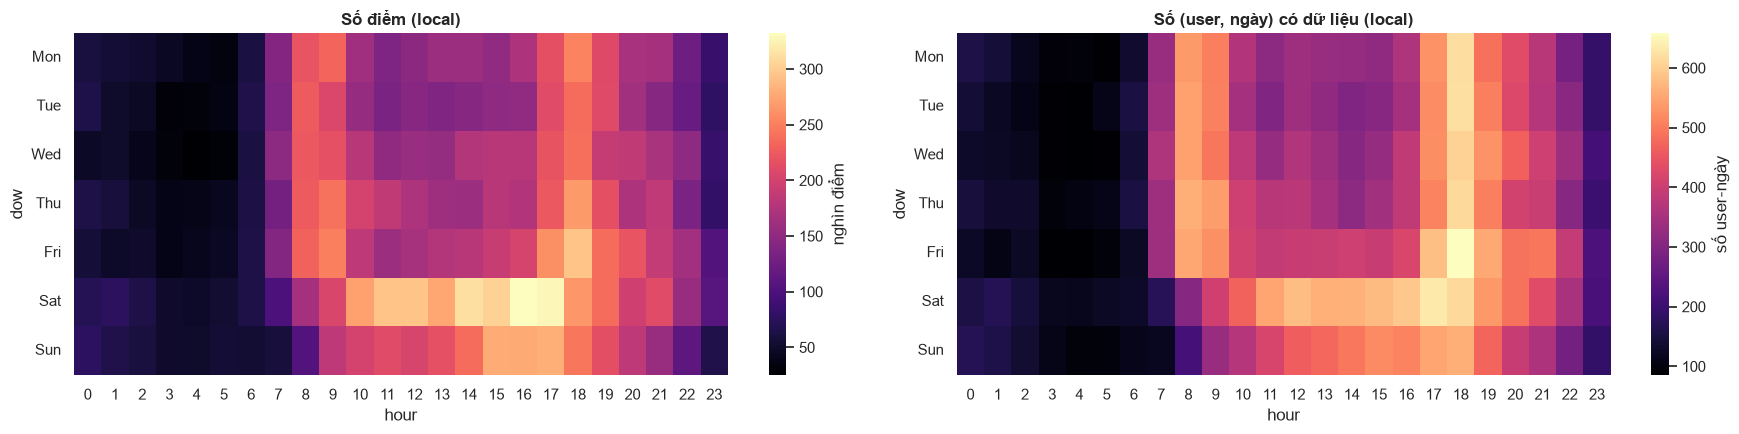

In [7]:
hd = pts.groupby(["dow", "hour"]).size().unstack(fill_value=0)
hd_user = pts.groupby(["user", "date", "dow", "hour"]).size().reset_index().groupby(["dow", "hour"]).size().unstack(fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
sns.heatmap(hd / 1e3, cmap="magma", ax=axes[0], cbar_kws={"label": "nghìn điểm"})
axes[0].set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0); axes[0].set_title("Số điểm (local)")
sns.heatmap(hd_user, cmap="magma", ax=axes[1], cbar_kws={"label": "số user-ngày"})
axes[1].set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0); axes[1].set_title("Số (user, ngày) có dữ liệu (local)")
plt.tight_layout(); savefig("03_heatmap_dow_hour"); plt.show()

In [8]:
dow_share = pts.groupby("dow").size() / len(pts) * 100
print("% điểm theo ngày trong tuần (0=Mon):\n", dow_share.round(2))
print(f"Weekend chiếm {dow_share.loc[[5, 6]].sum():.1f}% điểm (kỳ vọng nếu đều: 28.6%)")

% điểm theo ngày trong tuần (0=Mon):
 dow
0   13.0600
1   12.3400
2   13.2000
3   13.9100
4   14.8400
5   18.0200
6   14.6300
dtype: float64
Weekend chiếm 32.7% điểm (kỳ vọng nếu đều: 28.6%)


### 3.1 Ngày lễ Trung Quốc & sự kiện

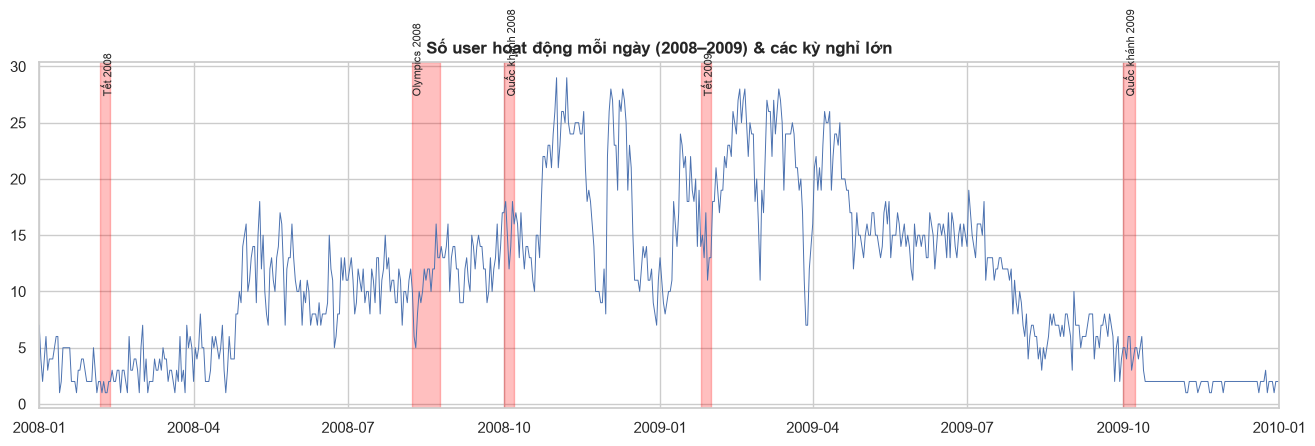

In [9]:
daily = pts.groupby("date").agg(n=("user", "size"), users=("user", "nunique"))
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(daily.index, daily.users, lw=0.7)
events = {"Olympics 2008": ("2008-08-08", "2008-08-24"),
          "Quốc khánh 2008": ("2008-10-01", "2008-10-07"), "Tết 2009": ("2009-01-25", "2009-01-31"),
          "Quốc khánh 2009": ("2009-10-01", "2009-10-08"), "Tết 2008": ("2008-02-06", "2008-02-12")}
for name, (a, b) in events.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=0.25, color="red")
    ax.text(pd.Timestamp(a), daily.users.max() * 0.95, name, fontsize=8, rotation=90)
ax.set_xlim(pd.Timestamp("2008-01-01"), pd.Timestamp("2010-01-01"))
ax.set_title("Số user hoạt động mỗi ngày (2008–2009) & các kỳ nghỉ lớn"); savefig("03_daily_users_holidays"); plt.show()

In [10]:
# Trong kỳ nghỉ, user có rời Bắc Kinh nhiều hơn không?
pts["is_holiday"] = False
for a, b in events.values():
    pts.loc[pts.date.between(pd.Timestamp(a), pd.Timestamp(b)), "is_holiday"] = True
pts.groupby("is_holiday").in_beijing.mean().rename("% trong Bắc Kinh") * 100

is_holiday
False   79.9935
True    43.6343
Name: % trong Bắc Kinh, dtype: float64

## 4. Độ phủ ban đêm & giờ hành chính (tiền đề home/office)

Định nghĩa (giờ local, có thể tinh chỉnh sau):
- **Night window**: 22:00–06:00 (gán đêm cho ngày bắt đầu).
- **Work window**: Thứ 2–6, 09:00–18:00.

Do người dùng thường **tắt ghi khi đến nơi**, đếm điểm trong window sẽ thiếu; NB05 sẽ bổ sung bằng gap giữa các trajectory.

In [11]:
night = (pts.hour >= 22) | (pts.hour < 6)
work = (pts.dow < 5) & pts.hour.between(9, 17)
pts["night_date"] = (pts.ts_local - pd.Timedelta(hours=6)).dt.normalize()
print(f"% điểm ban đêm (22–6h): {night.mean():.2%}")
print(f"% điểm giờ hành chính (T2–T6 9–18h): {work.mean():.2%}")
cov = pd.DataFrame({
    "active_days": pts.groupby("user").date.nunique(),
    "nights_with_data": pts[night].groupby("user").night_date.nunique(),
    "workdays_with_data": pts[work].groupby("user").date.nunique(),
}).fillna(0).astype(int)
print(cov.describe(percentiles=[.25, .5, .75, .9]))

% điểm ban đêm (22–6h): 14.55%
% điểm giờ hành chính (T2–T6 9–18h): 32.37%


       active_days  nights_with_data  workdays_with_data
count     182.0000          182.0000            182.0000
mean       61.2912           22.7747             31.8352
std       131.6167           47.0601             66.6703
min         1.0000            0.0000              0.0000
25%         7.0000            2.0000              3.0000
50%        21.5000            7.0000             10.5000
75%        63.0000           21.7500             31.0000
90%       133.3000           55.8000             80.0000
max     1,252.0000          335.0000            555.0000


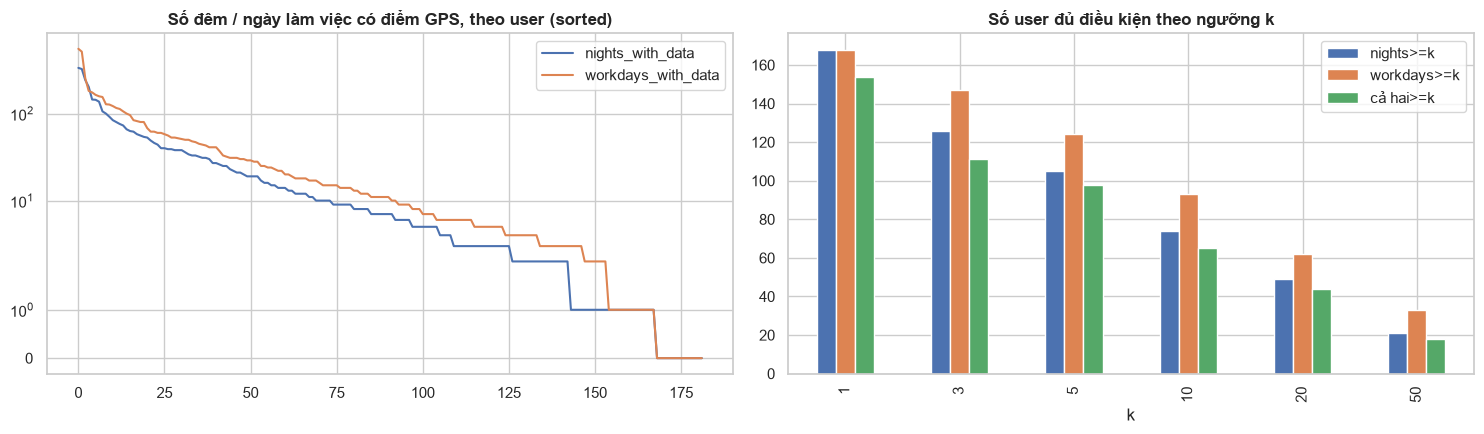

,nights>=k,workdays>=k,cả hai>=k
1,168,168,154
3,126,147,111
5,105,124,98
10,74,93,65
20,49,62,44
50,21,33,18


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for c in ["nights_with_data", "workdays_with_data"]:
    s = cov[c].sort_values(ascending=False).reset_index(drop=True)
    ax[0].plot(s.index, s.values, label=c)
ax[0].set_yscale("symlog"); ax[0].legend(); ax[0].set_title("Số đêm / ngày làm việc có điểm GPS, theo user (sorted)")
thr = [1, 3, 5, 10, 20, 50]
feas = pd.DataFrame({"nights>=k": [(cov.nights_with_data >= k).sum() for k in thr],
                     "workdays>=k": [(cov.workdays_with_data >= k).sum() for k in thr],
                     "cả hai>=k": [((cov.nights_with_data >= k) & (cov.workdays_with_data >= k)).sum() for k in thr]}, index=thr)
feas.plot.bar(ax=ax[1]); ax[1].set_title("Số user đủ điều kiện theo ngưỡng k"); ax[1].set_xlabel("k")
plt.tight_layout(); savefig("03_night_work_coverage"); plt.show()
feas

## 5. Giờ bắt đầu / kết thúc trajectory (local)

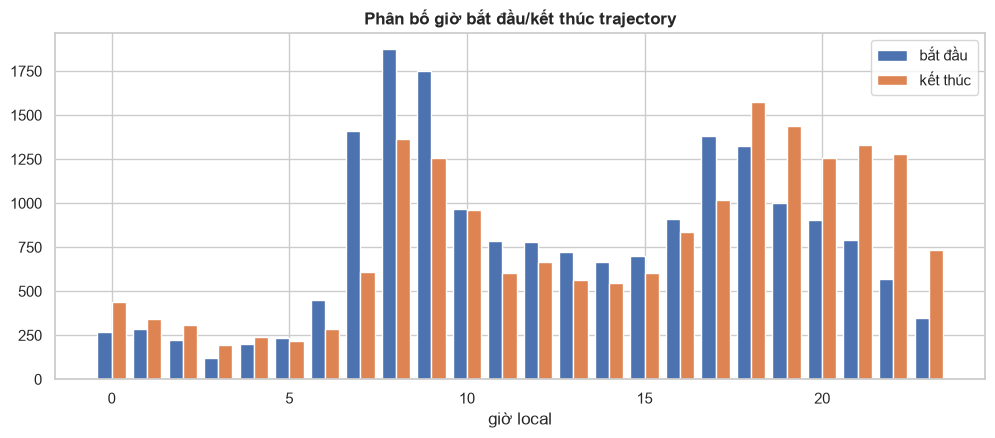

% traj kéo qua nửa đêm: 0.05511811023622047


In [13]:
tj = pts.groupby(["user", "traj_id"], observed=True).agg(start=("ts_local", "min"), end=("ts_local", "max"))
fig, ax = plt.subplots(figsize=(12, 4.5))
s = tj.start.dt.hour.value_counts().sort_index(); e = tj.end.dt.hour.value_counts().sort_index()
ax.bar(s.index - 0.2, s.values, width=0.4, label="bắt đầu"); ax.bar(e.index + 0.2, e.values, width=0.4, label="kết thúc")
ax.legend(); ax.set_xlabel("giờ local"); ax.set_title("Phân bố giờ bắt đầu/kết thúc trajectory")
savefig("03_traj_start_end_hour"); plt.show()
print("% traj kéo qua nửa đêm:", (tj.start.dt.date != tj.end.dt.date).mean())

**Insight:** đỉnh bắt đầu ~7–9h và kết thúc ~17–20h (đi làm / về nhà) → điểm **đầu tiên buổi sáng** và **cuối cùng buổi tối**
của mỗi ngày là proxy mạnh cho vị trí nhà; điểm cuối buổi sáng/đầu buổi chiều là proxy cho nơi làm việc.

## 6. Thời lượng ghi mỗi ngày

Số giờ có ghi GPS / (user, ngày):
count   11,155.0000
mean         2.3090
std          2.4449
min          0.0000
25%          0.6522
50%          1.4328
75%          3.1138
90%          5.5951
99%         10.9823
max         23.4111
Name: ts_utc, dtype: float64


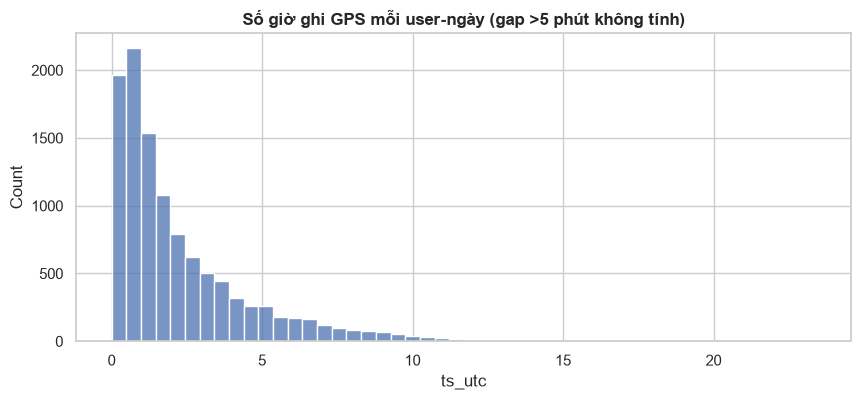

In [14]:
pts = pts.sort_values(["user", "traj_id", "ts_utc"])
dt = pts.groupby(["user", "traj_id"], observed=True).ts_utc.diff().dt.total_seconds().clip(upper=300)  # cap gap 5 phút
rec = dt.groupby([pts.user, pts.date]).sum() / 3600
print("Số giờ có ghi GPS / (user, ngày):")
print(rec.describe(percentiles=[.25, .5, .75, .9, .99]))
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(rec.clip(upper=24), bins=48, ax=ax); ax.set_title("Số giờ ghi GPS mỗi user-ngày (gap >5 phút không tính)")
savefig("03_hours_recorded_per_day"); plt.show()

**Insight:** median chỉ vài giờ/ngày → Geolife **không phải log liên tục 24/7** mà là log theo chuyến đi (trip-based).
Thời gian dừng dài (ở nhà, ở công ty) phần lớn rơi vào khoảng không ghi.